In [29]:
import numpy as np
import matplotlib.pyplot as plt

Logistic Regression implementation with Numpy

In [35]:
class LogisticRegression:
    def __init__(self, learning_rate=0.01, iterations=1000):
        self.lr = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = 0
        self.loss_history = []

    def sigmoid(self, z):
        """Sigmoid activation function"""
        return 1 / (1 + np.exp(-z))

    def loss(self, h, y):
        """Cross-entropy loss"""
        m = len(y)
        return - (1/m) * np.sum(y*np.log(h) + (1-y)*np.log(1-h))

    def fit(self, X, y):
        """Train model using gradient descent"""
        m, n = X.shape
        self.weights = np.zeros(n)

        for _ in range(self.iterations):
            z = np.dot(X, self.weights) + self.bias
            h = self.sigmoid(z)

            dw = (1/m) * np.dot(X.T, (h - y))
            db = (1/m) * np.sum(h - y)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

            self.loss_history.append(self.loss(h, y))

    def predict(self, X):
        """Make predictions"""
        return (self.sigmoid(np.dot(X, self.weights) + self.bias) >= 0.5).astype(int)

Train Dataset loading (MNIST)

In [ ]:
train_img_path = "../dataset/train/train-images.idx3-ubyte"
train_label_path = "../dataset/train/train-labels.idx1-ubyte"

X_train = np.fromfile(train_img_path, dtype=np.uint8, offset=16).reshape(-1, 784)
y_train = np.fromfile(train_label_path, dtype=np.uint8, offset=8)

train_mask = (y_train == 0) | (y_train == 1)
X_train = X_train[train_mask].astype(np.float64) / 255.0
y_train = y_train[train_mask].astype(np.float64)

print("Images shape:", X_train.shape)
print("Unique classes:", np.unique(y_train))

Images shape: (12665, 784)
Unique classes: [0. 1.]


Test Dataset loading (MNIST)

In [ ]:
test_img_path = "../dataset/test/t10k-images.idx3-ubyte"
test_label_path = "../dataset/test/t10k-labels.idx1-ubyte"

X_test = np.fromfile(test_img_path, dtype=np.uint8, offset=16).reshape(-1, 784)
y_test = np.fromfile(test_label_path, dtype=np.uint8, offset=8)

# Only keep 0 and 1 images, remove 2-9 classes
test_mask = (y_test == 0) | (y_test == 1)
X_test = X_test[test_mask].astype(np.float64) / 255.0
y_test = y_test[test_mask].astype(np.float64)

print("Images shape:", X_test.shape)
print("Unique classes:", np.unique(y_test))

Images shape: (2115, 784)
Unique classes: [0. 1.]


Model training - Train data

In [38]:
model = LogisticRegression(learning_rate=0.01, iterations=1000)
model.fit(X_train, y_train)

Precision, recall and F1 score - Test data

In [42]:
for c in [0, 1]:
    tp = np.sum((predictions == c) & (y_test == c))
    fp = np.sum((predictions == c) & (y_test != c))
    fn = np.sum((predictions != c) & (y_test == c))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

    print(f"Class {c} -> Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")

Class 0 -> Precision: 1.0000 | Recall: 0.9980 | F1: 0.9990
Class 1 -> Precision: 0.9982 | Recall: 1.0000 | F1: 0.9991


Visualize loss function - Cross Entropy

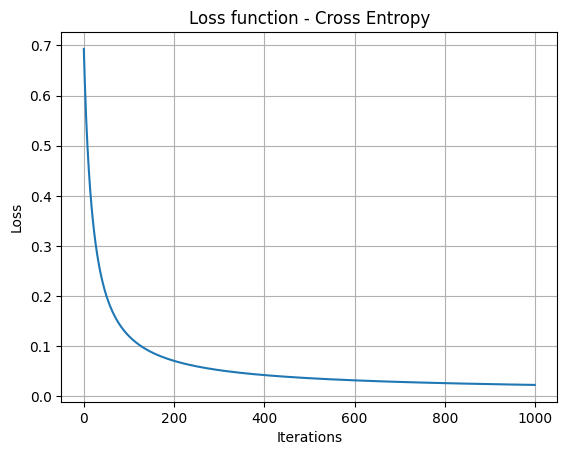

In [37]:
plt.plot(model.loss_history)
plt.title("Loss function - Cross Entropy")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid(True)
plt.show()